In [170]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix,classification_report
from sklearn.tree import DecisionTreeClassifier
import warnings
warnings.filterwarnings('ignore')

In [171]:
df=pd.read_csv('zoo.csv')
df.head()

,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


In [172]:
df.isnull().sum()

,0
animal_name,0
hair,0
feathers,0
eggs,0
milk,0
airborne,0
aquatic,0
predator,0
toothed,0
backbone,0


In [173]:
df[['hair','feathers']].corr()

,hair,feathers
hair,1.000000,-0.427851
feathers,-0.427851,1.000000


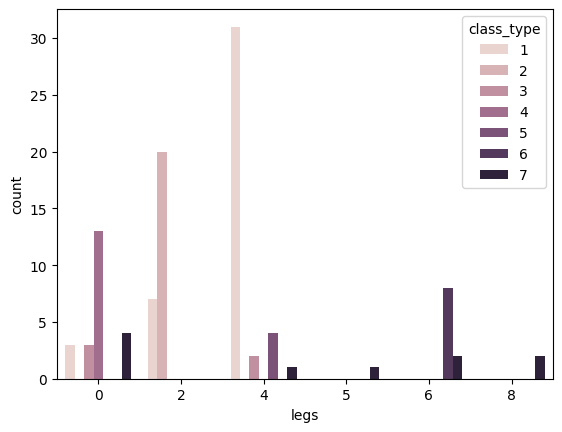

In [174]:
sns.countplot(data=df, x='legs', hue='class_type')
plt.show()

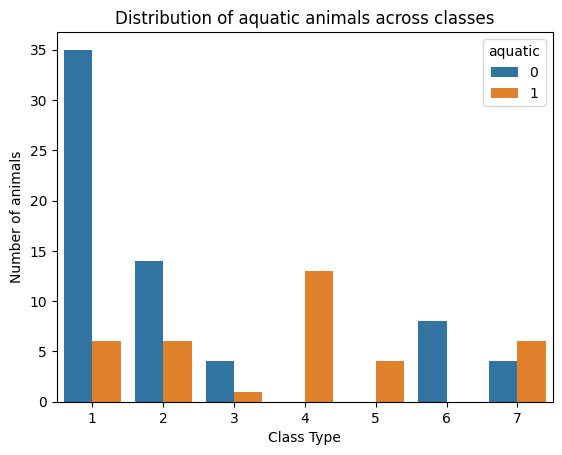

In [175]:
sns.countplot(data=df,x='class_type',hue='aquatic')
plt.title("Distribution of aquatic animals across classes")
plt.xlabel("Class Type")
plt.ylabel("Number of animals")
plt.legend(title='aquatic')
plt.show()

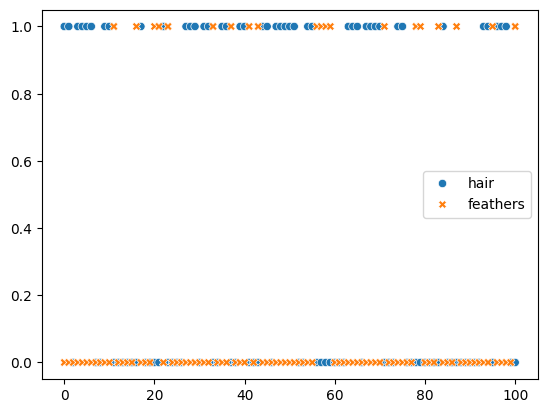

In [176]:
sns.scatterplot(df[['hair','feathers']])
plt.show()

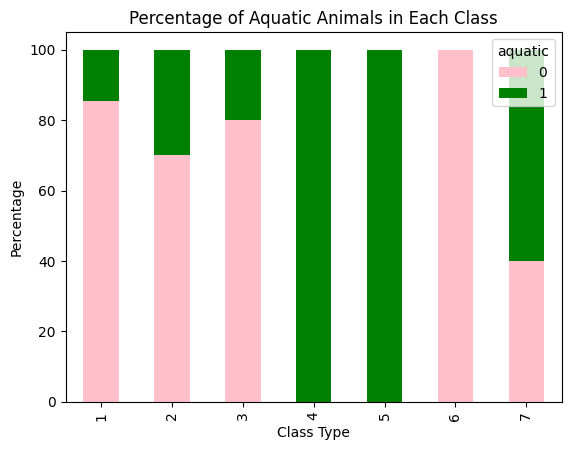

In [177]:
(pd.crosstab(df['class_type'], df['aquatic'],normalize='index')*100).plot(kind='bar',stacked=True,color=['pink','green'])
plt.title('Percentage of Aquatic Animals in Each Class')
plt.xlabel('Class Type')
plt.ylabel('Percentage')
plt.show()

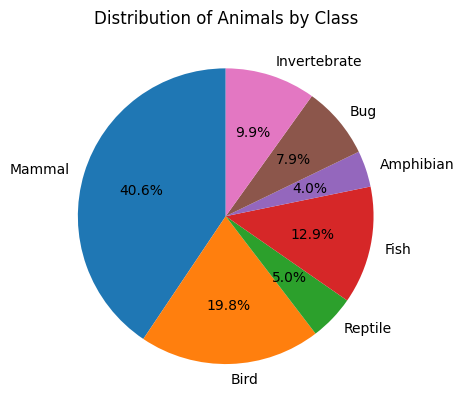

In [178]:
class_names = {1: 'Mammal',2: 'Bird',3: 'Reptile',4: 'Fish',5: 'Amphibian',6: 'Bug',7: 'Invertebrate'}
class_counts = df['class_type'].value_counts().sort_index()
plt.pie(class_counts,labels=[class_names[i] for i in class_counts.index],autopct='%1.1f%%',startangle=90)
plt.title('Distribution of Animals by Class')
plt.show()

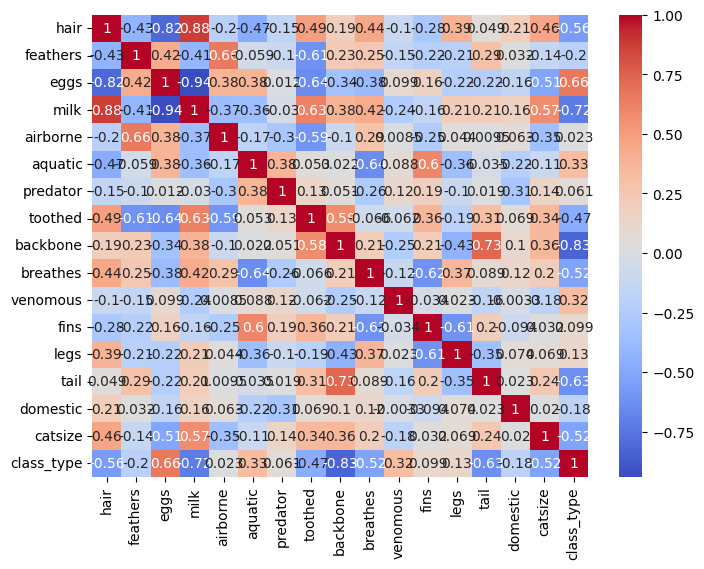

In [179]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm")

plt.show()

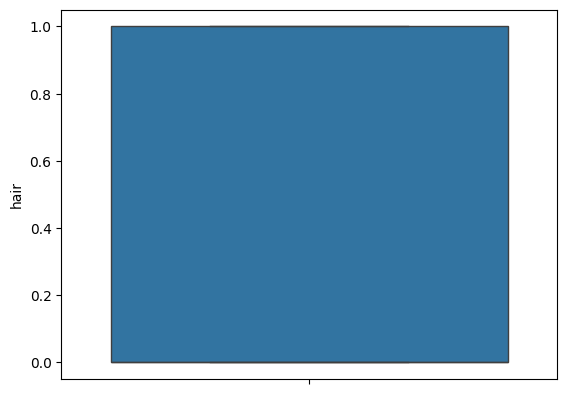

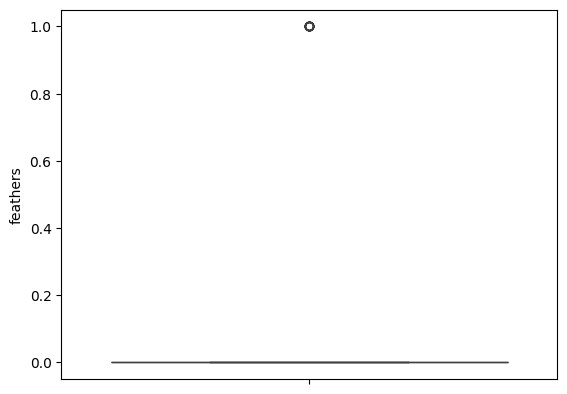

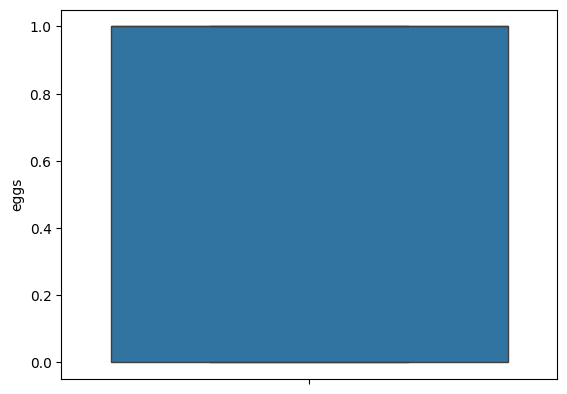

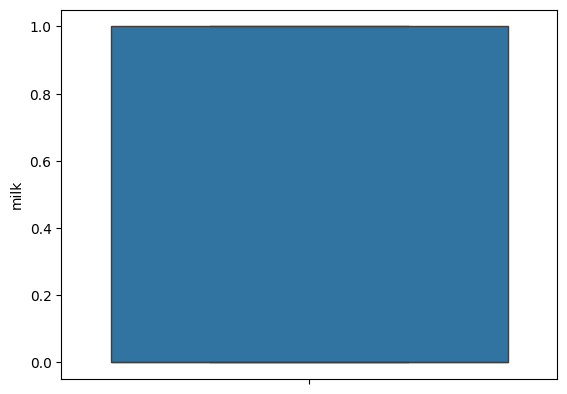

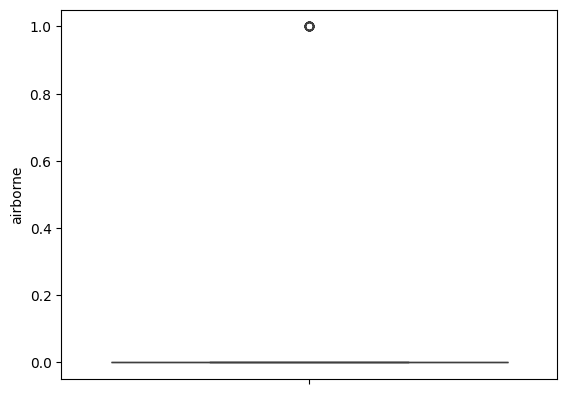

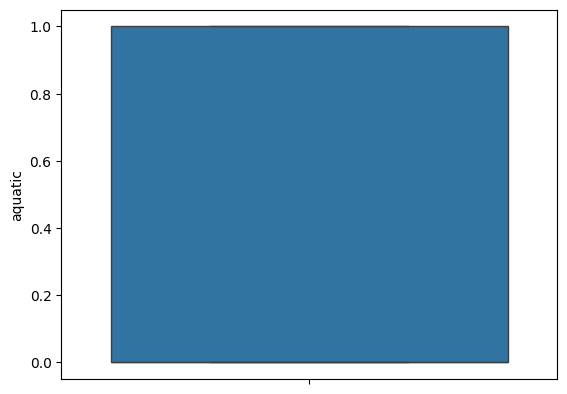

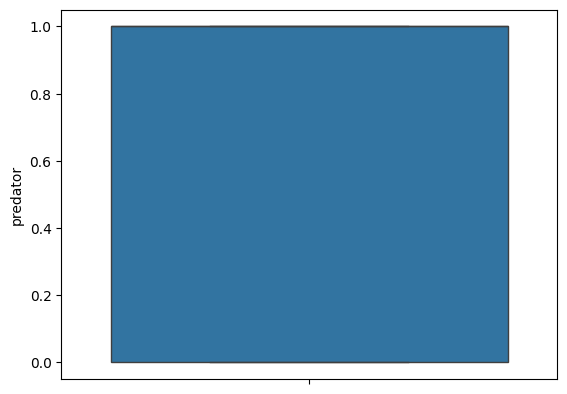

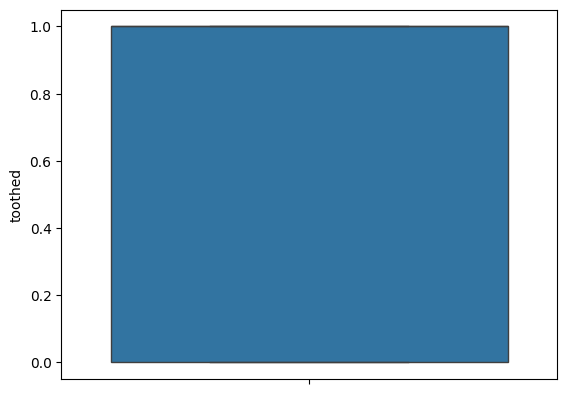

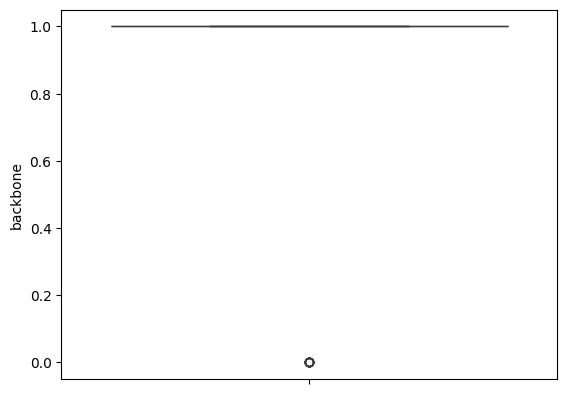

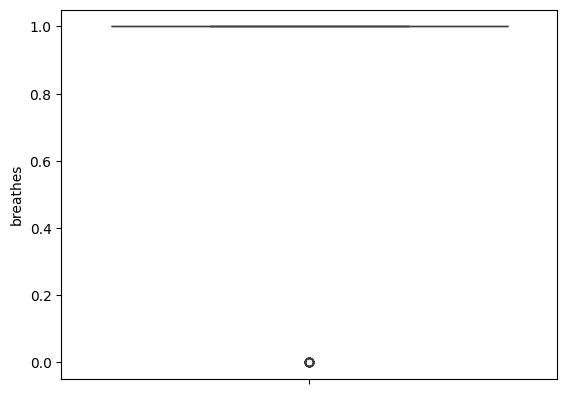

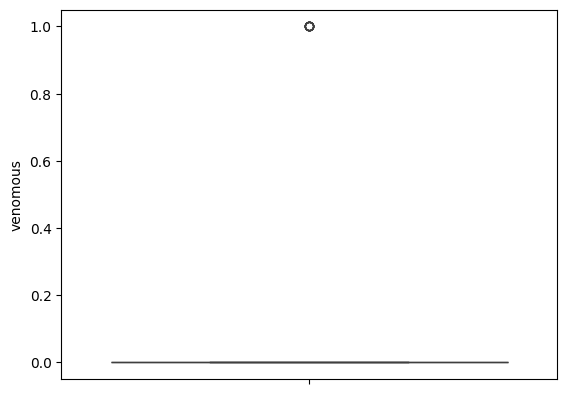

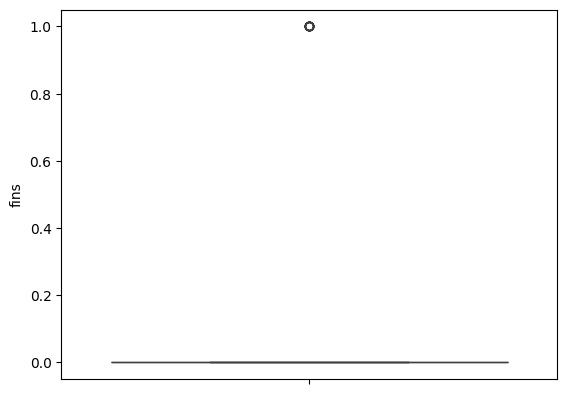

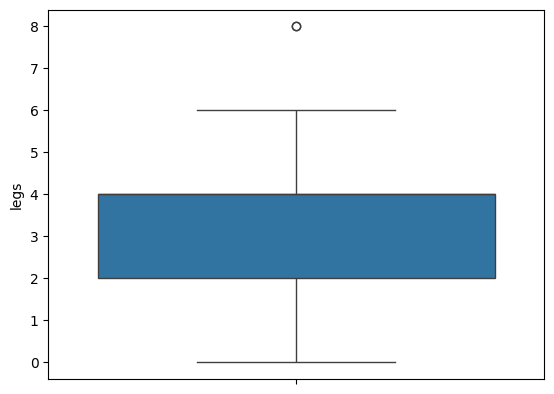

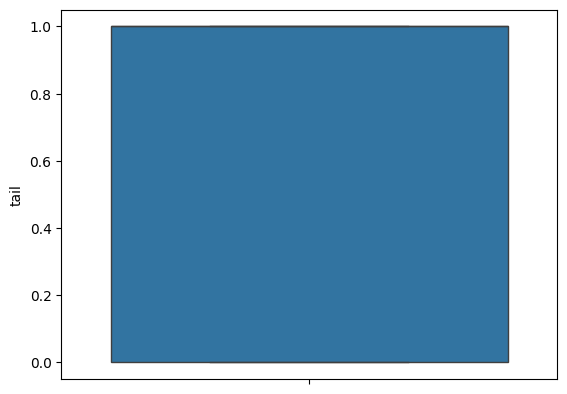

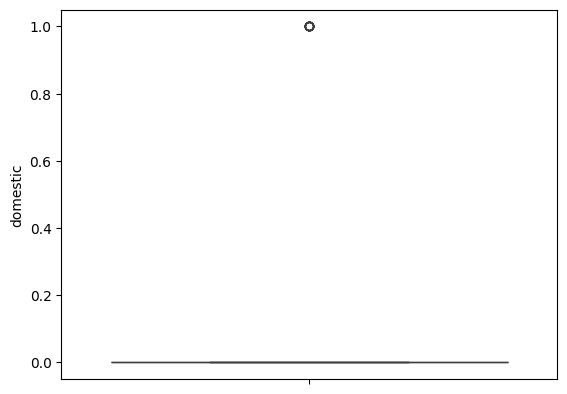

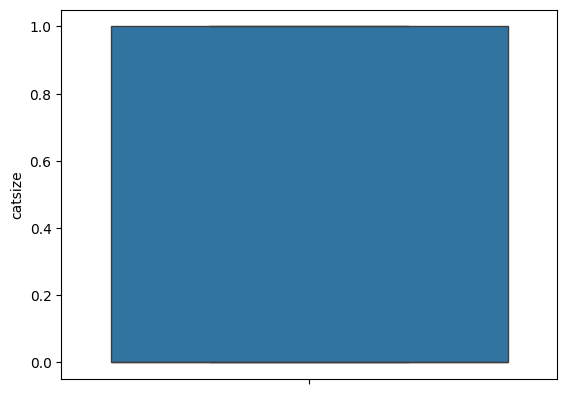

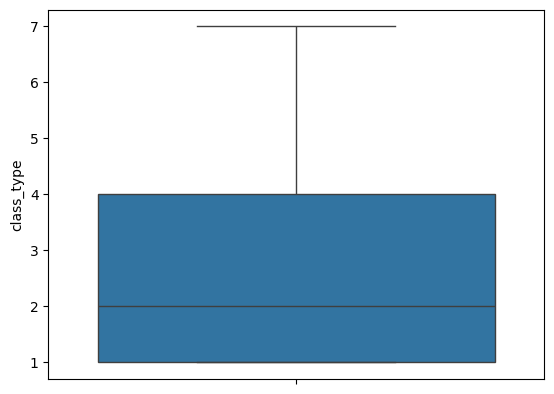

In [180]:
for cols in df.select_dtypes(include='number').columns:
  sns.boxplot(df[cols])
  plt.show()

In [181]:
x=df.drop(['animal_name','class_type'],axis=1)
print(x.columns)
y=df['class_type']
#print(y.columns)

Index(['hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 'predator',
       'toothed', 'backbone', 'breathes', 'venomous', 'fins', 'legs', 'tail',
       'domestic', 'catsize'],
      dtype='object')


In [182]:
from sklearn.model_selection import train_test_split


In [183]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

In [184]:
from sklearn.tree import DecisionTreeClassifier
gini_tree=DecisionTreeClassifier(criterion='gini',max_depth=5,random_state=35)

In [185]:
gini_tree.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=5, random_state=35)

In [186]:
df.columns

Index(['animal_name', 'hair', 'feathers', 'eggs', 'milk', 'airborne',
       'aquatic', 'predator', 'toothed', 'backbone', 'breathes', 'venomous',
       'fins', 'legs', 'tail', 'domestic', 'catsize', 'class_type'],
      dtype='object')

In [187]:
y_pred=gini_tree.predict(x_test)


In [188]:
import joblib

joblib.dump(gini_tree, "zoo_model(gini).pkl")


['zoo_model(gini).pkl']

In [189]:
#from google.colab import files
#files.download("zoo_model(gini).pkl")

In [190]:
import os

print(os.path.getsize("zoo_model(gini).pkl"))

3313


In [191]:
type(gini_tree)

sklearn.tree._classes.DecisionTreeClassifier

In [192]:
acc=accuracy_score(y_test,y_pred)
acc

0.9354838709677419

In [193]:
y_train_pred=gini_tree.predict(x_train)
acc_train=accuracy_score(y_train,y_train_pred)
acc_train

0.9714285714285714

In [194]:
confusion=confusion_matrix(y_test,y_pred)
print(confusion)

[[15  0  0  0  0  0  0]
 [ 0  3  0  0  0  0  0]
 [ 0  0  0  0  1  0  0]
 [ 0  0  0  2  0  0  0]
 [ 0  0  0  0  2  0  0]
 [ 0  0  0  0  0  4  1]
 [ 0  0  0  0  0  0  3]]


In [195]:
classification=classification_report(y_test,y_pred)
print(classification)


              precision    recall  f1-score   support

           1       1.00      1.00      1.00        15
           2       1.00      1.00      1.00         3
           3       0.00      0.00      0.00         1
           4       1.00      1.00      1.00         2
           5       0.67      1.00      0.80         2
           6       1.00      0.80      0.89         5
           7       0.75      1.00      0.86         3

    accuracy                           0.94        31
   macro avg       0.77      0.83      0.79        31
weighted avg       0.92      0.94      0.92        31



In [196]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(gini_tree, x, y, cv=5)

print(scores)
print("Average Accuracy:", scores.mean())

[0.95238095 0.85       0.9        0.85       0.9       ]
Average Accuracy: 0.8904761904761905


In [197]:
entropy_tree=DecisionTreeClassifier(criterion='entropy',max_depth=7,random_state=43)

In [198]:
entropy_tree.fit(x_train,y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=7, random_state=43)

In [199]:
y_pred_entropy=entropy_tree.predict(x_test)
acc=accuracy_score(y_test,y_pred)
acc

0.9354838709677419

In [200]:
acc=accuracy_score(y_test,y_pred_entropy)

In [201]:
y_train_pred_entropy=entropy_tree.predict(x_train)
acc_train=accuracy_score(y_train,y_train_pred)
acc_train

0.9714285714285714

In [202]:
con=confusion_matrix(y_test,y_pred)
con

array([[15,  0,  0,  0,  0,  0,  0],
       [ 0,  3,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  1,  0,  0],
       [ 0,  0,  0,  2,  0,  0,  0],
       [ 0,  0,  0,  0,  2,  0,  0],
       [ 0,  0,  0,  0,  0,  4,  1],
       [ 0,  0,  0,  0,  0,  0,  3]])

In [203]:
cla=classification_report(y_test,y_pred)
print(cla)

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        15
           2       1.00      1.00      1.00         3
           3       0.00      0.00      0.00         1
           4       1.00      1.00      1.00         2
           5       0.67      1.00      0.80         2
           6       1.00      0.80      0.89         5
           7       0.75      1.00      0.86         3

    accuracy                           0.94        31
   macro avg       0.77      0.83      0.79        31
weighted avg       0.92      0.94      0.92        31



In [204]:
from sklearn.model_selection import GridSearchCV
param_grid = {"criterion": ["gini", "entropy"],
    "max_depth": [3,5,7,None],
    "min_samples_split": [2,5,10],
    "min_samples_leaf": [1,2,4]}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42),param_grid,cv=5)
grid.fit(x_train, y_train)
print(grid.best_params_)
print(grid.best_score_)
grid_y_pred=grid.predict(x_test)
print(accuracy_score(y_test,grid_y_pred))


{'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 2}
0.9428571428571428
0.9354838709677419


In [205]:
new = ['yes','no','no','yes','no','no','no','yes','yes','yes','no','no',4,'yes','no','yes']
neww = []
for i in new:
    if i == 'yes':
        neww.append(1)
    elif i == 'no':
        neww.append(0)
    else:
        neww.append(i)

#print(neww)

ac = gini_tree.predict([neww])

if ac[0] == 1:
    print("mammal")
elif ac[0] == 2:
    print("bird")
elif ac[0] == 3:
    print("reptile")
elif ac[0] == 4:


    print("fish")

mammal


**KNN**

In [206]:
#-------------------------KNN-----------------------------------------

In [207]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [208]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [209]:
#scaler = StandardScaler()

#x_train = scaler.fit_transform(x_train)
#x_test = scaler.transform(x_test)
knn = KNeighborsClassifier()
knn.fit(x_train, y_train)

y_train_pred = knn.predict(x_train)
y_test_pred = knn.predict(x_test)

In [210]:
train_accuracy = accuracy_score(y_train, y_train_pred)
print("Train Accuracy:", train_accuracy)

test_accuracy = accuracy_score(y_test, y_test_pred)
print("Test Accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print(confusion)

print(classification_report(y_test, y_test_pred))

Train Accuracy: 0.9428571428571428
Test Accuracy: 0.9032258064516129
[[13  0  0  0  0  0  0]
 [ 0  6  0  0  0  0  0]
 [ 0  0  0  2  0  0  0]
 [ 0  0  0  4  0  0  0]
 [ 0  0  0  0  1  0  0]
 [ 0  0  0  0  0  2  0]
 [ 0  0  0  0  1  0  2]]
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00         6
           3       0.00      0.00      0.00         2
           4       0.67      1.00      0.80         4
           5       0.50      1.00      0.67         1
           6       1.00      1.00      1.00         2
           7       1.00      0.67      0.80         3

    accuracy                           0.90        31
   macro avg       0.74      0.81      0.75        31
weighted avg       0.88      0.90      0.88        31



In [211]:
scores = cross_val_score(knn,x,y, cv=2)

print(scores)
print("Average Accuracy:", scores.mean())
param_grid = {
    "n_neighbors": [5, 7, 9, 11],
    "weights": ["uniform"],
    "metric": ["euclidean", "manhattan", "minkowski"]
}

grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(x_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", grid.best_score_)

[0.84313725 0.82      ]
Average Accuracy: 0.8315686274509804
Best Parameters: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'uniform'}
Best CV Accuracy: 0.8574879227053139


In [212]:
best_knn = grid.best_estimator_

y_train_pred = best_knn.predict(x_train)
y_test_pred = best_knn.predict(x_test)

print("Train Accuracy:", accuracy_score(y_train, y_train_pred))
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))

print(confusion_matrix(y_test, y_test_pred))

print(classification_report(y_test, y_test_pred))


Train Accuracy: 0.9428571428571428
Test Accuracy: 0.9354838709677419
[[13  0  0  0  0  0  0]
 [ 0  6  0  0  0  0  0]
 [ 0  0  0  2  0  0  0]
 [ 0  0  0  4  0  0  0]
 [ 0  0  0  0  1  0  0]
 [ 0  0  0  0  0  2  0]
 [ 0  0  0  0  0  0  3]]
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00         6
           3       0.00      0.00      0.00         2
           4       0.67      1.00      0.80         4
           5       1.00      1.00      1.00         1
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         3

    accuracy                           0.94        31
   macro avg       0.81      0.86      0.83        31
weighted avg       0.89      0.94      0.91        31



In [213]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

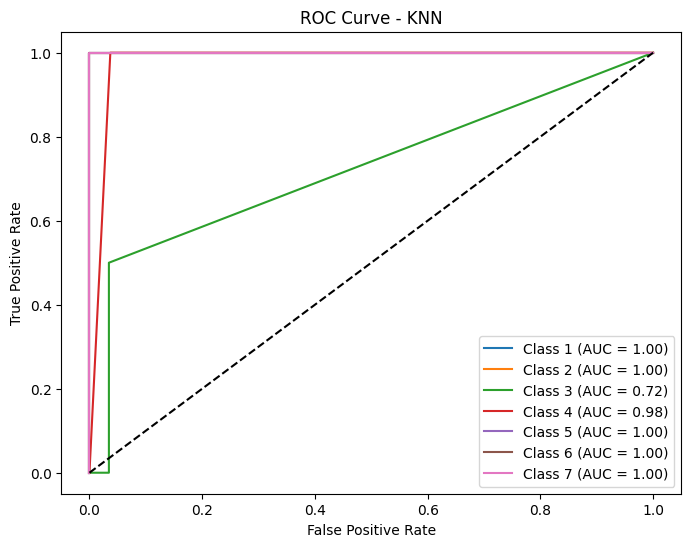

In [214]:
classes = [1, 2, 3, 4, 5, 6, 7]

y_test_bin = label_binarize(y_test, classes=classes)

y_score = best_knn.predict_proba(x_test)

plt.figure(figsize=(8,6))

for i in range(len(classes)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr,
             label=f"Class {classes[i]} (AUC = {roc_auc:.2f})")

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - KNN")

plt.legend()
plt.show()

In [215]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score

In [216]:
x_train, x_test, y_train, y_test = train_test_split(x, y,test_size=0.3,random_state=42,stratify=y)

In [217]:
nb = GaussianNB()
nb.fit(x_train, y_train)
y_train_pred = nb.predict(x_train)
y_test_pred = nb.predict(x_test)

In [218]:
train_accuracy = accuracy_score(y_train,y_train_pred)
print("Train Accuracy:", train_accuracy)
test_accuracy = accuracy_score(y_test,y_test_pred)
print("Test Accuracy:", test_accuracy)

confusion = confusion_matrix(y_test,y_test_pred)
print(confusion)
print(classification_report(y_test,y_test_pred))
cvs=cross_val_score(nb,x,y,cv=3)
print("Cross Validation Scores:",cvs)
print("Mean Cross Validation Score:",np.mean(cvs))

Train Accuracy: 1.0
Test Accuracy: 0.967741935483871
[[13  0  0  0  0  0  0]
 [ 0  6  0  0  0  0  0]
 [ 0  0  1  1  0  0  0]
 [ 0  0  0  4  0  0  0]
 [ 0  0  0  0  1  0  0]
 [ 0  0  0  0  0  2  0]
 [ 0  0  0  0  0  0  3]]
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00         6
           3       1.00      0.50      0.67         2
           4       0.80      1.00      0.89         4
           5       1.00      1.00      1.00         1
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         3

    accuracy                           0.97        31
   macro avg       0.97      0.93      0.94        31
weighted avg       0.97      0.97      0.96        31

Cross Validation Scores: [0.97058824 0.97058824 0.96969697]
Mean Cross Validation Score: 0.9702911467617351


Random Forest

In [219]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score



In [220]:
x=df.drop(['animal_name','class_type'],axis=1)
print(x.columns)
y=df['class_type']
#print(y.columns)

Index(['hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 'predator',
       'toothed', 'backbone', 'breathes', 'venomous', 'fins', 'legs', 'tail',
       'domestic', 'catsize'],
      dtype='object')


In [221]:
from sklearn.model_selection import train_test_split

In [222]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42,stratify=y)

In [223]:
rf=RandomForestClassifier(n_estimators=100,max_depth=4,min_samples_split=5,min_samples_leaf=3,random_state=42)


In [224]:
rf.fit(x_train,y_train)
y_pred=rf.predict(x_test)
y_prob = rf.predict_proba(x_test)

In [225]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt


In [226]:
classes = sorted(y.unique())
y_test_bin = label_binarize(y_test, classes=classes)
plt.figure(figsize=(8,6))

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

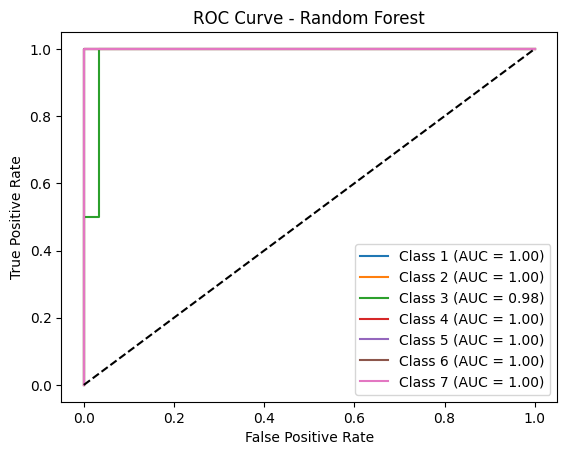

In [227]:
for i in range(len(classes)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr,
             label=f"Class {classes[i]} (AUC = {roc_auc:.2f})")

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.show()

In [228]:
cvs=cross_val_score(rf,x,y,cv=3)
print("Cross Validation Scores:",cvs)
print("Mean Cross Validation Score:",np.mean(cvs))

Cross Validation Scores: [0.94117647 0.91176471 0.90909091]
Mean Cross Validation Score: 0.9206773618538325


In [229]:
print("Accuracy Score:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:\n",confusion_matrix(y_test,y_pred))
print("Classification Report:")
cls=classification_report(y_test,y_pred)
print(cls)

Accuracy Score: 0.967741935483871
Confusion Matrix:
 [[13  0  0  0  0  0  0]
 [ 0  6  0  0  0  0  0]
 [ 0  0  1  1  0  0  0]
 [ 0  0  0  4  0  0  0]
 [ 0  0  0  0  1  0  0]
 [ 0  0  0  0  0  2  0]
 [ 0  0  0  0  0  0  3]]
Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00         6
           3       1.00      0.50      0.67         2
           4       0.80      1.00      0.89         4
           5       1.00      1.00      1.00         1
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         3

    accuracy                           0.97        31
   macro avg       0.97      0.93      0.94        31
weighted avg       0.97      0.97      0.96        31



In [230]:
train_pred = rf.predict(x_train)
test_pred = rf.predict(x_test)
print("Training Accuracy:", accuracy_score(y_train, train_pred))
print("Testing Accuracy:", accuracy_score(y_test, test_pred))

Training Accuracy: 0.9857142857142858
Testing Accuracy: 0.967741935483871


UNSEEN DATA

In [231]:
unseen=pd.read_csv('/content/unseen_all7classes_animals.csv')
unseen.head()
x=df.drop(['animal_name','class_type'],axis=1)
y=df['class_type']
unseenX=unseen.drop(['animal_name','class_type'],axis=1)
unseenY=unseen['class_type']

In [232]:
print("-------------------------------------UNSEEN DATA-------------------------------------")

unseen_pred=rf.predict(unseenX)
unseen_prob=rf.predict_proba(unseenX)

print("Unseen Dataset Accuracy:",accuracy_score(unseenY,unseen_pred))
print("Unseen ROC-AUC Score:",roc_auc_score(unseenY,unseen_prob,multi_class='ovr',average='macro'))

print("Unseen Confusion Matrix:\n",confusion_matrix(unseenY,unseen_pred))
print("Unseen Classification Report:\n",classification_report(unseenY,unseen_pred))

-------------------------------------UNSEEN DATA-------------------------------------
Unseen Dataset Accuracy: 0.9285714285714286
Unseen ROC-AUC Score: 0.9880952380952381
Unseen Confusion Matrix:
 [[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 2 0 0 0 0]
 [0 0 0 2 0 0 0]
 [0 0 0 1 1 0 0]
 [0 0 0 0 0 2 0]
 [0 0 0 0 0 0 2]]
Unseen Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00         2
           3       1.00      1.00      1.00         2
           4       0.67      1.00      0.80         2
           5       1.00      0.50      0.67         2
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2

    accuracy                           0.93        14
   macro avg       0.95      0.93      0.92        14
weighted avg       0.95      0.93      0.92        14



In [233]:
import joblib
joblib.dump(rf, "zoo_random_forest.pkl")
print("Model Saved Successfully")
import os
print(os.path.getsize("zoo_random_forest.pkl"))
import os
print(os.listdir())

Model Saved Successfully
180289
['.config', '.ipynb_checkpoints', 'zoo.csv', 'unseen_all7classes_animals.csv', 'zoo_model(gini).pkl', 'zoo_random_forest.pkl', 'sample_data']


In [234]:
from google.colab import files
files.download("zoo_random_forest.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Logistci Regression**

In [235]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

LR = LogisticRegression(
    max_iter=200,
    random_state=42
)

LR.fit(x_train, y_train)

y_pred = LR.predict(x_test)

print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

y_prob = LR.predict_proba(x_test)
roc_auc = roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro')
print("ROC-AUC Score:", roc_auc)

train_pred = LR.predict(x_train)
test_pred = LR.predict(x_test)

print("Training Accuracy:", accuracy_score(y_train, train_pred))
print("Testing Accuracy:", accuracy_score(y_test, test_pred))
cv_scores = cross_val_score(LR, x, y, cv=3)

print("Cross Validation Scores:", cv_scores)
print("Mean Cross Validation Accuracy:", cv_scores.mean())


Accuracy Score: 0.9354838709677419
Confusion Matrix:
 [[13  0  0  0  0  0  0]
 [ 0  6  0  0  0  0  0]
 [ 0  0  1  1  0  0  0]
 [ 0  0  0  4  0  0  0]
 [ 0  0  0  0  1  0  0]
 [ 0  0  0  0  0  2  0]
 [ 0  0  0  0  0  1  2]]
Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00         6
           3       1.00      0.50      0.67         2
           4       0.80      1.00      0.89         4
           5       1.00      1.00      1.00         1
           6       0.67      1.00      0.80         2
           7       1.00      0.67      0.80         3

    accuracy                           0.94        31
   macro avg       0.92      0.88      0.88        31
weighted avg       0.95      0.94      0.93        31

ROC-AUC Score: 0.9975369458128078
Training Accuracy: 1.0
Testing Accuracy: 0.9354838709677419
Cross Validation Scores: [0.97058824 0.91176471 0.90909091]
Me

**SVM(SVC)**

In [236]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

svc = SVC(
    kernel='rbf',
    C=1,
    probability=True,
    random_state=42
)

svc.fit(x_train, y_train)

y_pred = svc.predict(x_test)

print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

y_prob = svc.predict_proba(x_test)
roc_auc = roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro')
print("ROC-AUC Score:", roc_auc)

train_pred = svc.predict(x_train)
test_pred = svc.predict(x_test)

print("Training Accuracy:", accuracy_score(y_train, train_pred))
print("Testing Accuracy:", accuracy_score(y_test, test_pred))

cv_scores = cross_val_score(svc, x, y, cv=3)

print("Cross Validation Scores:", cv_scores)
print("Mean Cross Validation Accuracy:", cv_scores.mean())

Accuracy Score: 0.9354838709677419
Confusion Matrix:
 [[13  0  0  0  0  0  0]
 [ 0  6  0  0  0  0  0]
 [ 0  0  0  2  0  0  0]
 [ 0  0  0  4  0  0  0]
 [ 0  0  0  0  1  0  0]
 [ 0  0  0  0  0  2  0]
 [ 0  0  0  0  0  0  3]]
Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00         6
           3       0.00      0.00      0.00         2
           4       0.67      1.00      0.80         4
           5       1.00      1.00      1.00         1
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         3

    accuracy                           0.94        31
   macro avg       0.81      0.86      0.83        31
weighted avg       0.89      0.94      0.91        31

ROC-AUC Score: 0.9884471029791227
Training Accuracy: 0.9571428571428572
Testing Accuracy: 0.9354838709677419
Cross Validation Scores: [0.94117647 0.88235294

In [237]:
import pandas as pd
comparison_data = {
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "K-Nearest Neighbors ",
        "Gaussian Naïve Bayes",
        "Support Vector Machine",
        "Random Forest"
    ],

    "Accuracy": [0.9677, 0.9355, 0.9355, 0.9677, 0.9355, 0.9677],

    "Precision (Weighted Avg)": [0.97, 0.92, 0.89, 0.97, 0.89, 0.97],

    "Recall (Weighted Avg)": [0.97, 0.94, 0.94, 0.97, 0.94, 0.97],

    "F1-Score (Weighted Avg)": [0.96, 0.92, 0.91, 0.96, 0.91, 0.96],

    "Training Accuracy": [0.94, 0.9429, 0.9429, 1.0000, 0.9571, 0.9877],

    "Testing Accuracy": [0.9677, 0.9355, 0.9355, 0.9677, 0.9355, 0.9677],

    "Mean Cross Validation Score": [0.9571, 0.9429, 0.8575, 0.9207, 0.8705, 0.9702]
}
comparison_df = pd.DataFrame(comparison_data)
print("\nModel Comparison Table\n")
display(comparison_df.round(4))


Model Comparison Table



,Model,Accuracy,Precision (Weighted Avg),Recall (Weighted Avg),F1-Score (Weighted Avg),Training Accuracy,Testing Accuracy,Mean Cross Validation Score
0,Logistic Regression,0.9677,0.97,0.97,0.96,0.9400,0.9677,0.9571
1,Decision Tree,0.9355,0.92,0.94,0.92,0.9429,0.9355,0.9429
2,K-Nearest Neighbors,0.9355,0.89,0.94,0.91,0.9429,0.9355,0.8575
3,Gaussian Naïve Bayes,0.9677,0.97,0.97,0.96,1.0000,0.9677,0.9207
4,Support Vector Machine,0.9355,0.89,0.94,0.91,0.9571,0.9355,0.8705
5,Random Forest,0.9677,0.97,0.97,0.96,0.9877,0.9677,0.9702
